# BrushCue Example: Pinch Image

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/pinch_image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/pinch-image

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


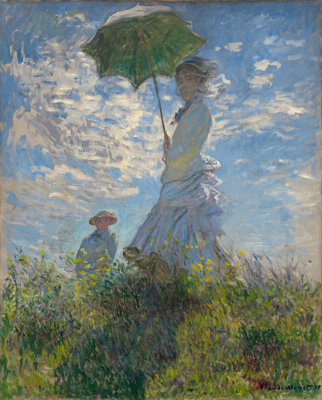

In [1]:
import io
from PIL import Image

import brushcue as bc

amount = 0.4
radius = 1.0
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
center = bc.Point2f.from_components(
    (input_bounds.min_x() + (input_bounds.width() / 2.0)),
    (input_bounds.min_y() + (input_bounds.height() / 2.0)),
)
effect_radius = (input_bounds.width().min(input_bounds.height()) / 2.0) * radius
graph = input_image.point_effect_shader(
    "let n = clamp(distance_from_center / effect_radius, 0.0001, 1.0);\nlet factor = pow(sin(1.5707964 * n), -amount);\nlet offset = position - effect_center_point;\nlet source_distance = min(distance_from_center * factor, effect_radius);\nlet source = effect_center_point + offset / max(distance_from_center, 0.0001) * source_distance;\nreturn sample(clamp(source, image_bounds.xy + vec2<f32>(0.5), image_bounds.zw - vec2<f32>(0.5)));",
    "",
    center,
    effect_radius,
    bc.Dictionary.create().add("amount", amount).add("image_bounds", input_bounds),
    bc.ColorRepresentation.srgb(),
).crop(input_bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
